In [12]:
!pip install roboflow
!pip install pycocotools

import os
import torch
from torch.utils.data import DataLoader
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.transforms import functional as F
from pycocotools.coco import COCO
from PIL import Image
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


In [13]:
from roboflow import Roboflow
rf = Roboflow(api_key="YKjKJq9jwCbXAUxun5s3")
project = rf.workspace("work-4u6cx").project("i-segmentation-akjbc")
version = project.version(3)
dataset = version.download("coco-segmentation")


loading Roboflow workspace...
loading Roboflow project...


In [14]:
class CocoDataset(torch.utils.data.Dataset):
    def __init__(self, root, annotation, transforms=None):
        self.root = root
        self.coco = COCO(annotation)
        self.ids = list(self.coco.imgs.keys())
        self.transforms = transforms

    def __getitem__(self, index):
        coco = self.coco
        img_id = self.ids[index]
        ann_ids = coco.getAnnIds(imgIds=img_id)
        anns = coco.loadAnns(ann_ids)

        path = coco.loadImgs(img_id)[0]['file_name']
        img = Image.open(os.path.join(self.root, path)).convert("RGB")

        masks, boxes, labels = [], [], []
        for ann in anns:
            if ann['iscrowd']:
                continue
            masks.append(coco.annToMask(ann))
            x, y, width, height = ann['bbox']
            boxes.append([x, y, x + width, y + height])
            labels.append(ann['category_id'])

        masks = torch.as_tensor(np.array(masks), dtype=torch.uint8)
        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "masks": masks,
            "image_id": torch.tensor([img_id]),
        }

        if self.transforms:
            img = self.transforms(img)

        return img, target

    def __len__(self):
        return len(self.ids)


In [15]:
train_dataset = CocoDataset(
    root=os.path.join(dataset.location, "train"),
    annotation=os.path.join(dataset.location, "train", "_annotations.coco.json"),
    transforms=F.to_tensor
)
train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True, collate_fn=lambda x: tuple(zip(*x)))


loading annotations into memory...
Done (t=0.77s)
creating index...
index created!


In [16]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model = maskrcnn_resnet50_fpn(pretrained=True)
model.to(device)
model.train()

optimizer = torch.optim.SGD([p for p in model.parameters() if p.requires_grad],
                            lr=0.005, momentum=0.9, weight_decay=0.0005)


The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MaskRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.


In [17]:
num_epochs = 300
for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    for images, targets in train_loader:
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()
        total_loss += losses.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {total_loss:.4f}")


Epoch [1/300], Loss: 1914.4442
Epoch [2/300], Loss: 1446.2959
Epoch [3/300], Loss: 1281.3941
Epoch [4/300], Loss: 1189.5901
Epoch [5/300], Loss: 1108.6847
Epoch [6/300], Loss: 1039.7115
Epoch [7/300], Loss: 1002.5243
Epoch [8/300], Loss: 1002.0813
Epoch [9/300], Loss: 944.0234
Epoch [10/300], Loss: 913.5887
Epoch [11/300], Loss: 890.3540
Epoch [12/300], Loss: 888.3694
Epoch [13/300], Loss: 876.0666
Epoch [14/300], Loss: 840.1527
Epoch [15/300], Loss: 819.0385
Epoch [16/300], Loss: 836.5660
Epoch [17/300], Loss: 869.6976
Epoch [18/300], Loss: 790.0793
Epoch [19/300], Loss: 902.5705
Epoch [20/300], Loss: 774.1200
Epoch [21/300], Loss: 800.5850
Epoch [22/300], Loss: 770.2029
Epoch [23/300], Loss: 775.0860
Epoch [24/300], Loss: 754.1451
Epoch [25/300], Loss: 786.8420
Epoch [26/300], Loss: 752.5908
Epoch [27/300], Loss: 705.5006
Epoch [28/300], Loss: 752.8097
Epoch [29/300], Loss: 741.6867
Epoch [30/300], Loss: 728.3464
Epoch [31/300], Loss: 763.3092
Epoch [32/300], Loss: 749.6204
Epoch [33


Classification Report:

                 precision    recall  f1-score   support

        Adaptor       0.45      0.27      0.33       319
      Allen Key       0.00      0.00      0.00        42
     Bit Holder       0.39      0.35      0.37       179
     Bit Socket       0.77      0.70      0.73      2567
           Bits       0.90      0.69      0.79       685
    Deep Socket       0.81      0.90      0.85     20804
  Extension Bar       0.73      0.61      0.66      2711
    Flex Handle       0.31      0.33      0.32       459
Long bit socket       0.61      0.47      0.53      1399
  Rachet Handle       0.79      0.56      0.65      1463
       S Handle       0.75      0.36      0.48       707
        Sockets       0.89      0.89      0.89     25752
       Spanners       0.47      0.06      0.11       108
universal joint       0.81      0.57      0.67       971

       accuracy                           0.83     58166
      macro avg       0.62      0.48      0.53     58166
   w

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


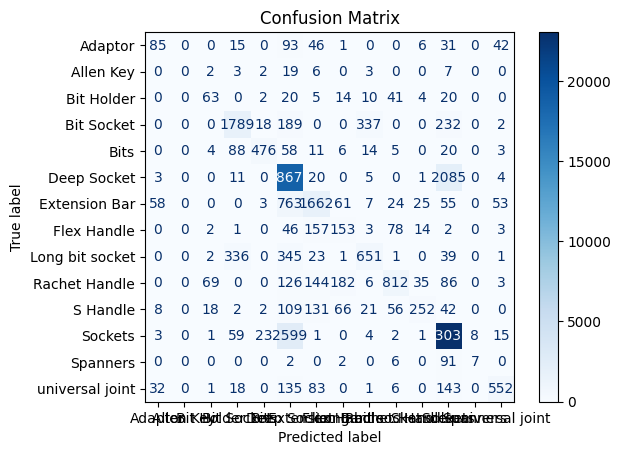

In [18]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Get the class ID to name mapping from COCO
coco = train_dataset.coco
id2name = {cat['id']: cat['name'] for cat in coco.loadCats(coco.getCatIds())}

# Get the actually used label IDs in your predictions and ground truths
used_label_ids = sorted(list(set(matched_gt_labels + matched_pred_labels)))

# Extract the corresponding class names
used_class_labels = [id2name[i] for i in used_label_ids]

# Print classification report
print("\nClassification Report:\n")
print(classification_report(
    matched_gt_labels,
    matched_pred_labels,
    labels=used_label_ids,
    target_names=used_class_labels
))

# Plot confusion matrix
cm = confusion_matrix(matched_gt_labels, matched_pred_labels, labels=used_label_ids)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=used_class_labels)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()


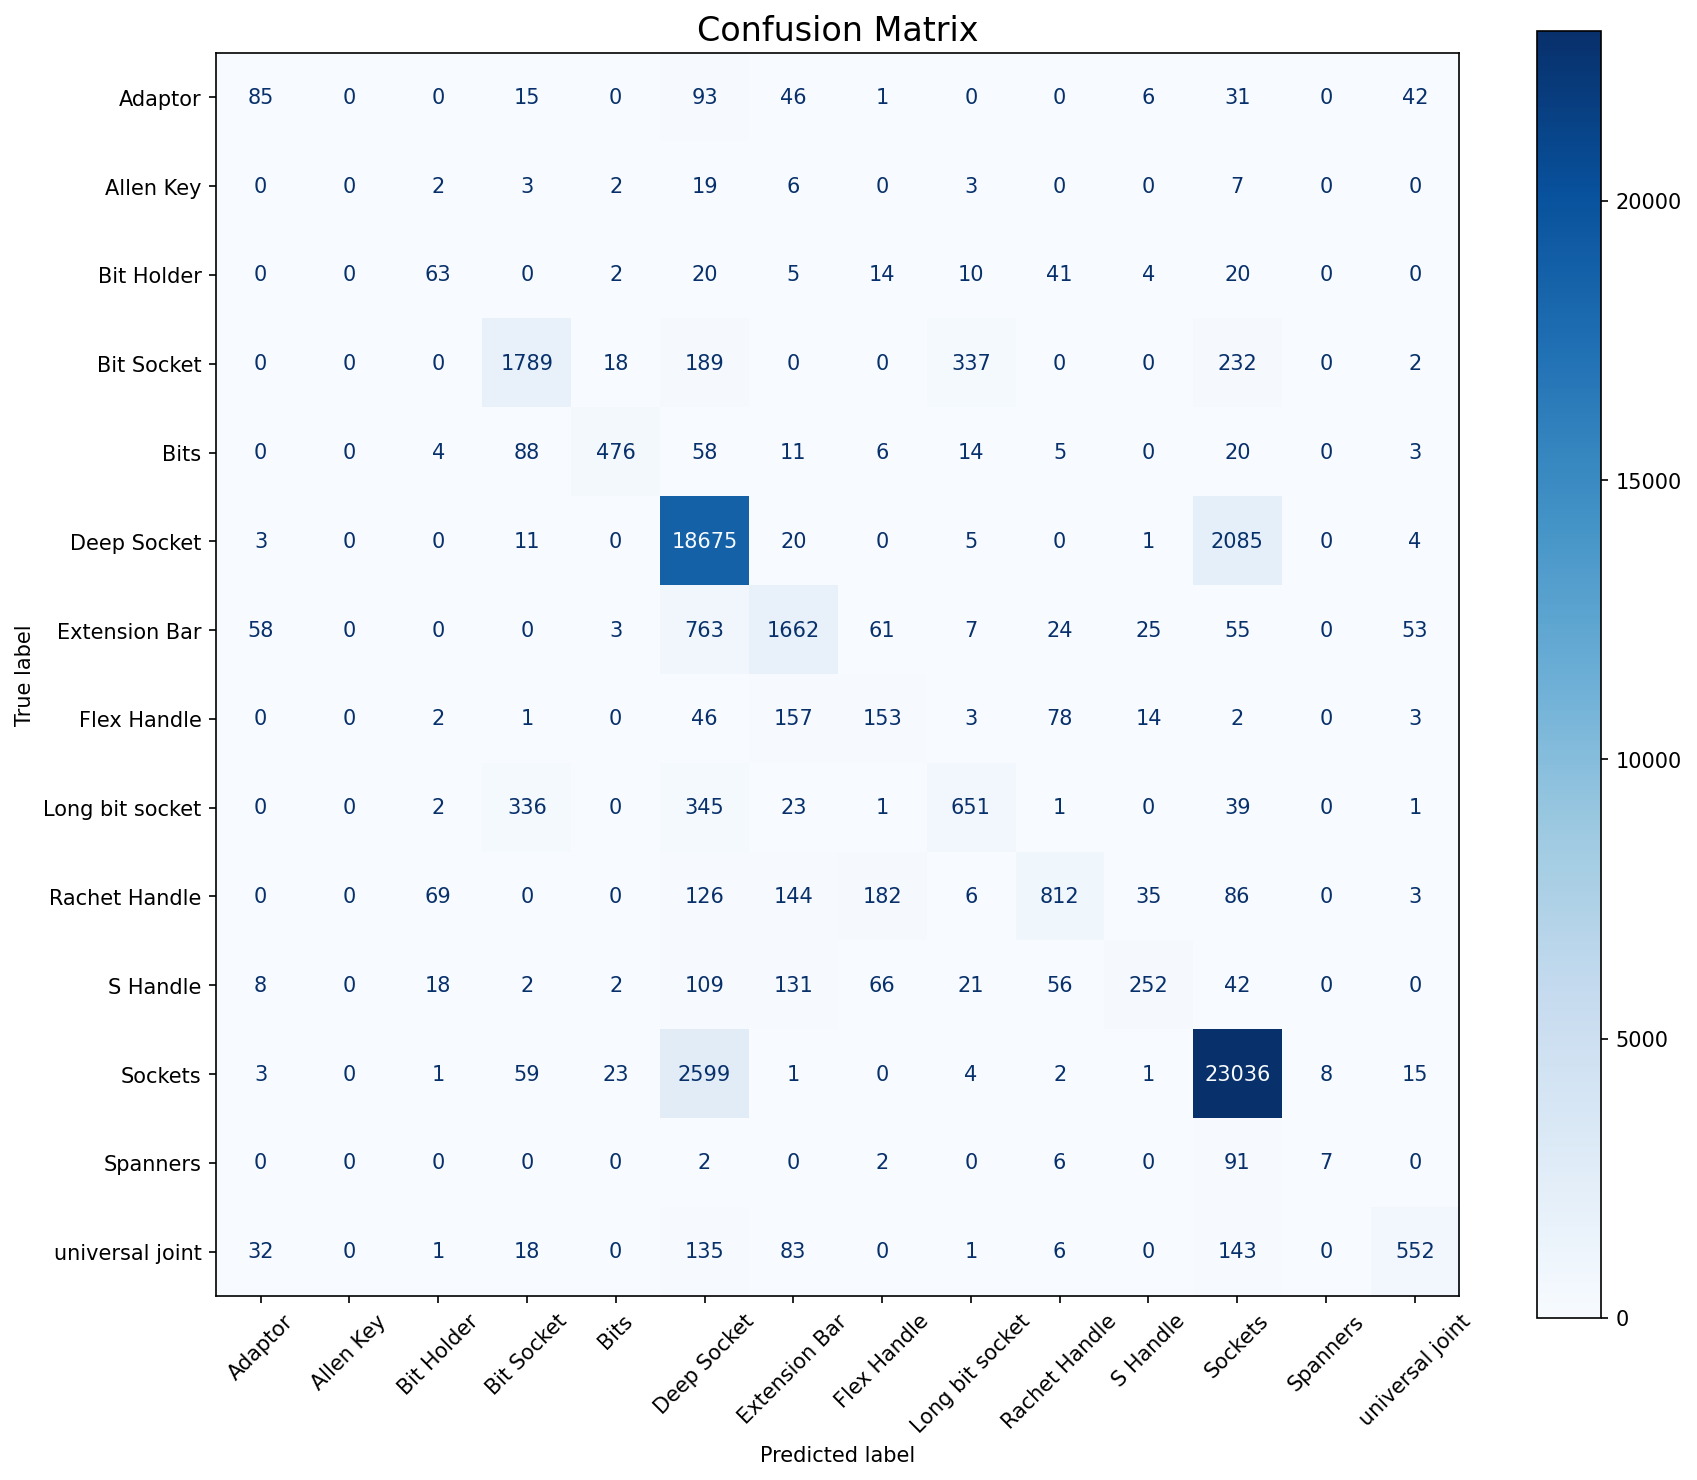

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Reuse your variables: `cm` and `used_class_labels`
# cm = confusion_matrix(matched_gt_labels, matched_pred_labels, labels=used_label_ids)

fig, ax = plt.subplots(figsize=(12, 10), dpi=150)  # Increase figure size and resolution
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=used_class_labels)
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45, values_format='d')

plt.title("Confusion Matrix", fontsize=16)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()


In [20]:
# Save the model weights
save_path = "maskrcnn_roboflow_weights.pth"
torch.save(model.state_dict(), save_path)
print(f"Model weights saved to: {save_path}")


Model weights saved to: maskrcnn_roboflow_weights.pth
